# 09 · Handle spoken intake

What changes when a ticket arrives as speech?

Evaluate a speech recogniser on public audio and an original equipment-ID readout slice with clean and matched noisy clips. Replay the transcription through the same intent and citation pipeline. Compare text versus speech on the common slice only.

**Measures** — Word error rate, identifier exactness, end-task accuracy and real-time factor.

**Evidence** — Aligned transcripts and text-to-speech-input failure analysis.

**Runtime** — T4 speech profile. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}
LAB_NUMBER = 9

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


## Hear the F-250 request

A signed-in operator reads the equipment plate and asks for the maximum
operating temperature. The desk needs the exact identifier before it can
cite a manual. Keep the words, speaker, and timing fixed. What should the
desk do if noise changes the identifier in the transcript?

Readouts are original synthetic speech. They use known manual and follow-up
fixtures from the development split, rephrased to say the asset ID aloud.
The public audiobook slice measures word recognition in a separate domain.
[Read Lesson 9](https://docs.recohut.com/courses/advanced-ai-systems-engineering/3-connect-tools-and-inputs/09-handle-spoken-intake).

In [6]:
from io import BytesIO
from math import gcd
import shutil
from tempfile import TemporaryDirectory
from urllib.request import urlopen

import numpy as np
from scipy.io import wavfile
from scipy.signal import resample_poly

PUBLIC_REVISION = "5be91486e11a2d616f4ec5db8d3fd248585ac07a"
PUBLIC_FILE = (
    "https://huggingface.co/datasets/hf-internal-testing/librispeech_asr_dummy/resolve/"
    f"{PUBLIC_REVISION}/clean/validation-00000-of-00001.parquet"
)
PUBLIC_SHA256 = "4e69a06fa5edc90921e5e7e39a7084881f8b3ed9c805c574f4f39c6fde27c603"
PUBLIC_CLIPS = 8
RATE = 16000
SNR_DB = 12
VOICE = "en-us"
WORDS_PER_MINUTE = 150
DECODE = {"language": "en", "task": "transcribe", "num_beams": 1, "do_sample": False, "max_new_tokens": 96}
DOMAINS = ("Clean readout", "Noisy readout", "LibriSpeech")
DIGITS = dict(zip("0123456789", "zero one two three four five six seven eight nine".split()))
WORD_DIGITS = {word: digit for digit, word in DIGITS.items()}
READOUTS = (
    "What is the maximum temperature for {asset}?",
    "Please read the operating temperature limit for {asset}.",
)

development = cases("dev")
tickets = [row for row in development if row["slice"] in {"manual", "follow_up"} and row["variant"] < len(READOUTS)]
assert digest(development) == SPLIT_MANIFEST["dev"]["sha256"]
assert len(tickets) == 8 and len({row["family"] for row in tickets}) == 4
assert all(row["decision"] == "answer" and row["source"] == "manual" for row in tickets)
opening_ticket = next(row for row in tickets if row["id"] == "F250-00")
print(f"Matched readouts: {len(tickets)} | equipment families: 4 | noise: {SNR_DB} dB SNR")

def equipment_readout(ticket):
    letter, identifier = ticket["asset"].split("-")
    spoken_id = f"{letter} {' '.join(DIGITS[digit] for digit in identifier)}"
    return READOUTS[ticket["variant"]].format(asset=spoken_id)

Matched readouts: 8 | equipment families: 4 | noise: 12 dB SNR


## Create the clean and noisy clips

Add seeded white noise to a copy of the same waveform. Scale that noise
relative to signal power. The synthetic pair isolates one noise setting.
It holds the voice, recording setup, and noise family fixed.

In [7]:
def load_synthesiser():
    if COURSE_SMOKE:
        return None, "fixture tone"
    executable = shutil.which("espeak-ng") or shutil.which("espeak")
    if not executable:
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "-qq", "espeak-ng"], check=True)
        executable = shutil.which("espeak-ng")
    if not executable:
        raise RuntimeError("eSpeak NG was not available after installation")
    return executable, subprocess.check_output([executable, "--version"], text=True).splitlines()[0]


synthesiser, synthesiser_version = load_synthesiser()


def clip_for(text):
    if COURSE_SMOKE:
        position = np.arange(RATE, dtype=np.float32)
        return (0.5 * np.sin(position / 8)).astype(np.float32)
    with TemporaryDirectory() as directory:
        path = Path(directory) / "clip.wav"
        subprocess.run(
            [synthesiser, "-v", VOICE, "-s", str(WORDS_PER_MINUTE), "-w", str(path), text],
            check=True,
        )
        source_rate, pcm = wavfile.read(path)
    assert pcm.ndim == 1 and pcm.dtype == np.int16
    common = gcd(source_rate, RATE)
    wave = resample_poly(pcm.astype(np.float32) / 32768, RATE // common, source_rate // common)
    assert 0 < len(wave) < RATE * 30
    return wave


def matched_pair(wave, seed):
    rng = np.random.default_rng(seed)
    noise = rng.standard_normal(len(wave)).astype(np.float32)
    gain = np.linalg.norm(wave) / (np.linalg.norm(noise) * 10 ** (SNR_DB / 20))
    noisy_wave = wave + gain * noise
    scale = max(1.0, float(np.max(np.abs(wave))), float(np.max(np.abs(noisy_wave))))
    clean, noisy = wave / scale, noisy_wave / scale
    measured_snr_db = float(20 * np.log10(np.linalg.norm(clean) / np.linalg.norm(noisy - clean)))
    assert abs(measured_snr_db - SNR_DB) < 0.01
    return {"clean": clean, "noisy": noisy, "snr_db": measured_snr_db}


def public_clips():
    if COURSE_SMOKE:
        return [{"id": "fixture", "reference": "example English passage", "audio": clip_for("")}]
    import pyarrow.parquet as pq
    import soundfile as sf

    with urlopen(PUBLIC_FILE, timeout=90) as response:
        payload = response.read()
    assert hashlib.sha256(payload).hexdigest() == PUBLIC_SHA256
    parquet = pq.ParquetFile(BytesIO(payload))
    batch = next(parquet.iter_batches(batch_size=PUBLIC_CLIPS, columns=["audio", "text", "id"]))
    rows = []
    for row in batch.to_pylist():
        wave, rate = sf.read(BytesIO(row["audio"]["bytes"]), dtype="float32")
        assert rate == RATE and wave.ndim == 1 and 0 < len(wave) < RATE * 30
        rows.append({"id": row["id"], "reference": row["text"], "audio": wave})
    assert len(rows) == PUBLIC_CLIPS
    return rows


clips = []
for ticket in tickets:
    reference = equipment_readout(ticket)
    noise_seed = int(ticket["family"][1:]) * 10 + ticket["variant"]
    pair = matched_pair(clip_for(reference), seed=noise_seed)
    clips.extend([
        {"id": ticket["id"], "domain": DOMAINS[0], "reference": reference, "audio": pair["clean"],
         "ticket": ticket, "noise_seed": None, "snr_db": None},
        {"id": ticket["id"], "domain": DOMAINS[1], "reference": reference, "audio": pair["noisy"],
         "ticket": ticket, "noise_seed": noise_seed, "snr_db": pair["snr_db"]},
    ])
clips.extend({**row, "domain": DOMAINS[2], "ticket": None, "noise_seed": None, "snr_db": None}
             for row in public_clips())

## Decide what can reach the manual

Extract one recognised equipment ID. Both the trusted text and the
dictated transcript go through the same resolver. An unknown ID or two
different IDs means asking again. Lookup uses the authenticated tenant
and role. This fixture only handles questions about the temperature limit.

In [8]:
def words(text):
    return re.findall(r"[a-z0-9]+", text.lower())


def extract_equipment(text):
    tokens = words(text)
    matches = set()
    for index, token in enumerate(tokens):
        compact = re.fullmatch(r"([fpv])([0-9]{3})", token)
        if compact:
            matches.add(f"{compact[1].upper()}-{compact[2]}")
        if token not in {"f", "p", "v"}:
            continue
        digits = []
        for token_after in tokens[index + 1:]:
            if token_after.isdigit():
                digits.append(token_after)
            elif token_after in WORD_DIGITS:
                digits.append(WORD_DIGITS[token_after])
            else:
                break
        identifier = "".join(digits)
        if len(identifier) == 3:
            matches.add(f"{token.upper()}-{identifier}")
    return sorted(matches)


def resolve(text, tenant, role):
    identifiers = extract_equipment(text)
    asset_id = identifiers[0] if len(identifiers) == 1 else None
    if role != "operator" or tenant not in TENANTS:
        return asset_id, {"decision": "deny", "value": "", "evidence": []}
    matching = next((asset for asset in assets("dev") if asset["asset"] == asset_id and asset["tenant"] == tenant), None)
    if matching is None:
        return asset_id, {"decision": "clarify", "value": "", "evidence": []}
    return asset_id, {"decision": "answer", "value": str(matching["limit"]), "evidence": [matching["manual_id"]]}


assert extract_equipment("Limit for F two five zero?") == extract_equipment("F250 / F-250") == ["F-250"]
assert extract_equipment("F-250 or P two one zero?") == ["F-250", "P-210"]
assert resolve("F-250 or P-210", opening_ticket["tenant"], opening_ticket["role"])[1]["decision"] == "clarify"
assert resolve("F-250", opening_ticket["tenant"], "guest")[1]["decision"] == "deny"

## Decode each clip and record elapsed time

Load Whisper once and warm it with one clip. Measure each subsequent
pipeline call including feature extraction, decoding, and text
post-processing. Audio loading, resampling, and lookup fall outside the
timed call. The same decoding options apply to both audio domains.

In [9]:
if COURSE_SMOKE:
    load_seconds, warmup_seconds = None, None
else:
    from transformers import pipeline

    repo, revision = MODEL_IDS["speech"]
    use_cuda = torch.cuda.is_available()
    t0 = time.perf_counter()
    recogniser = pipeline(
        "automatic-speech-recognition",
        model=repo,
        revision=revision,
        device=0 if use_cuda else -1,
        torch_dtype=torch.float16 if use_cuda else torch.float32,
    )
    sync()
    load_seconds = time.perf_counter() - t0

    def transcribe(wave):
        return recogniser(
            {"array": wave, "sampling_rate": RATE}, generate_kwargs=DECODE,
        )["text"].strip()

    t0 = time.perf_counter()
    transcribe(clips[0]["audio"])
    sync()
    warmup_seconds = time.perf_counter() - t0
    if use_cuda:
        torch.cuda.reset_peak_memory_stats()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/290M [00:00<?, ?B/s]

generation_config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (4 outputs left out)

special_tokens_map.json: 0.00B [00:00, ?B/s]

preprocessor_config.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


/usr/local/lib/python3.13/dist-packages/transformers/models/whisper/generation_whisper.py:573: FutureWarning: The input name `inputs` is deprecated. Please make sure to use `input_features` instead.
  warnings.warn(
You have passed task=transcribe, but also have set `forced_decoder_ids` to [[1, None], [2, 50359]] which creates a conflict. `forced_decoder_ids` will be ignored in favor of task=transcribe.


## Compare word edits with the exact answer

Normalise case and punctuation for word errors. Digit words and digit
strings still occupy different tokens in this metric. The equipment
parser can resolve both to the same ID. Score matched helpdesk inputs by
decision, exact value, and cited evidence. Audiobook clips have no manual
lookup or equipment outcome.

In [10]:
def edit_distance(reference, prediction):
    previous = list(range(len(prediction) + 1))
    for i, word in enumerate(reference, 1):
        current = [i]
        for j, token in enumerate(prediction, 1):
            current.append(min(current[-1] + 1, previous[j] + 1, previous[j - 1] + (word != token)))
        previous = current
    return previous[-1]


def grade_clip(clip, prediction, seconds):
    reference = words(clip["reference"])
    record = {
        "id": clip["id"], "domain": clip["domain"], "reference": clip["reference"], "prediction": prediction,
        "word_errors": edit_distance(reference, words(prediction)), "reference_words": len(reference),
        "seconds": seconds, "duration": len(clip["audio"]) / RATE,
        "noise_seed": clip["noise_seed"], "snr_db": clip["snr_db"],
    }
    ticket = clip["ticket"]
    if ticket is None:
        return record

    expected = {key: ticket[key] for key in ("decision", "value", "evidence")}
    text_id, text_answer = resolve(clip["reference"], ticket["tenant"], ticket["role"])
    predicted_id, speech_answer = resolve(prediction, ticket["tenant"], ticket["role"])
    assert text_id == ticket["asset"] and score_answer(ticket, text_answer) == 1
    return {
        **record, "family": ticket["family"], "slice": ticket["slice"], "variant": ticket["variant"],
        "tenant": ticket["tenant"], "role": ticket["role"],
        "expected_id": ticket["asset"], "predicted_id": predicted_id,
        "identifier_correct": predicted_id == ticket["asset"],
        "expected": expected, "text_answer": text_answer, "speech_answer": speech_answer,
        "text_correct": score_answer(ticket, text_answer), "task_correct": score_answer(ticket, speech_answer),
    }


assert edit_distance("a b c".split(), "a x".split()) == 2
records = []
for clip in clips:
    if COURSE_SMOKE:
        prediction, seconds = clip["reference"], None
    else:
        sync()
        t0 = time.perf_counter()
        prediction = transcribe(clip["audio"])
        sync()
        seconds = time.perf_counter() - t0
    records.append(grade_clip(clip, prediction, seconds))
peak_allocated_bytes = torch.cuda.max_memory_allocated() if not COURSE_SMOKE and use_cuda else None

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


## Inspect the exact failure path for one digit

After saving this cell's evidence, play the clean and noisy F-250 clips
from the two WAV files and read the saved transcripts.
Compare the recogniser's actual outputs with a controlled transcript edit
that changes only the final digit. That edit illustrates the resolver's
response independently of the recorded recogniser errors.

In [11]:
def preview_audio(domain, filename):
    clip = next(row for row in clips if row["id"] == opening_ticket["id"] and row["domain"] == domain)
    wave = clip["audio"]
    path = Path("evidence") / filename
    path.parent.mkdir(exist_ok=True)
    wavfile.write(path, RATE, np.rint(wave * 32767).astype(np.int16))
    return {
        "path": path,
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        "envelope": [{"min": float(part.min()), "max": float(part.max())} for part in np.array_split(wave, 64)],
    }


opening = {row["domain"]: row for row in records if row["id"] == opening_ticket["id"] and row["domain"] in DOMAINS[:2]}
edited = opening[DOMAINS[0]]["reference"].replace("F two five zero", "F two five one")
assert edited != opening[DOMAINS[0]]["reference"]
new_id, new_answer = resolve(edited, opening_ticket["tenant"], opening_ticket["role"])
assert new_id == "F-251" and new_answer["decision"] == "clarify"
save("opening", {
    "case_id": opening_ticket["id"],
    "manual": {"id": opening_ticket["evidence"][0], "text": manual_text(opening_ticket)},
    "clean_audio": preview_audio(DOMAINS[0], "f250-clean.wav"),
    "noisy_audio": preview_audio(DOMAINS[1], "f250-noisy.wav"),
    "clean": opening[DOMAINS[0]],
    "noisy": opening[DOMAINS[1]],
    "controlled_edit": {"prediction": edited, "predicted_id": new_id, "speech_answer": new_answer},
})
print(json.dumps({domain: {key: row[key] for key in (
    "reference", "prediction", "predicted_id", "speech_answer", "task_correct"
)} for domain, row in opening.items()}, indent=2))

Evidence saved to evidence/opening.json
{
  "Clean readout": {
    "reference": "What is the maximum temperature for F two five zero?",
    "prediction": "What is the maximum temperature for F250?",
    "predicted_id": "F-250",
    "speech_answer": {
      "decision": "answer",
      "value": "101",
      "evidence": [
        "manual-F-250-r3"
      ]
    },
    "task_correct": 1
  },
  "Noisy readout": {
    "reference": "What is the maximum temperature for F two five zero?",
    "prediction": "What in the maximum temperature for a 2-I-Nero?",
    "predicted_id": null,
    "speech_answer": {
      "decision": "clarify",
      "value": "",
      "evidence": []
    },
    "task_correct": 0
  }
}


## Make paired comparisons on the development tickets

Use total word edits divided by total reference words per domain.
Equipment and answer accuracy use only the matched readouts. Resample by
equipment family to account for repeated wording. Treat intervals from
this small set as descriptive and keep the public slice separate.

{
  "rows": [
    {
      "domain": "Clean readout",
      "n": 8,
      "word_errors": 31,
      "reference_words": 84,
      "wer": 0.36904761904761907,
      "duration": 31.9260625,
      "real_time_factor": 0.029131087242610945,
      "median_seconds": 0.11720993750031994,
      "exact_ids": 5,
      "wrong_ids": 0,
      "unresolved_ids": 3,
      "text_passes": 8,
      "task_passes": 5
    },
    {
      "domain": "Noisy readout",
      "n": 8,
      "word_errors": 36,
      "reference_words": 84,
      "wer": 0.42857142857142855,
      "duration": 31.9260625,
      "real_time_factor": 0.03160483163242605,
      "median_seconds": 0.12307889949988748,
      "exact_ids": 0,
      "wrong_ids": 0,
      "unresolved_ids": 8,
      "text_passes": 8,
      "task_passes": 0
    },
    {
      "domain": "LibriSpeech",
      "n": 8,
      "word_errors": 18,
      "reference_words": 205,
      "wer": 0.08780487804878048,
      "duration": 86.345,
      "real_time_factor": 0.025531046383696

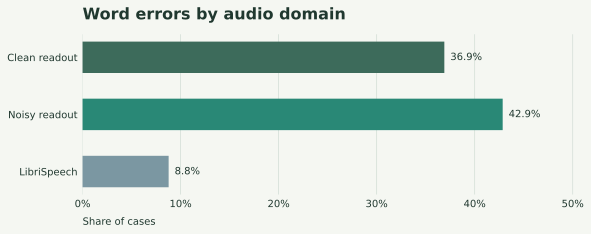

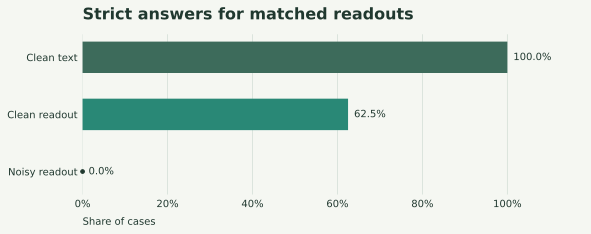

In [12]:
rows_by_domain = {domain: [row for row in records if row["domain"] == domain] for domain in DOMAINS}
summary = []
for domain, rows in rows_by_domain.items():
    word_errors = sum(row["word_errors"] for row in rows)
    reference_words = sum(row["reference_words"] for row in rows)
    duration = sum(row["duration"] for row in rows)
    result = {
        "domain": domain, "n": len(rows), "word_errors": word_errors, "reference_words": reference_words,
        "wer": word_errors / reference_words, "duration": duration,
        "real_time_factor": None if COURSE_SMOKE else sum(row["seconds"] for row in rows) / duration,
        "median_seconds": None if COURSE_SMOKE else float(np.median([row["seconds"] for row in rows])),
    }
    if domain != DOMAINS[2]:
        result.update(
            exact_ids=sum(row["identifier_correct"] for row in rows),
            wrong_ids=sum(row["predicted_id"] is not None and not row["identifier_correct"] for row in rows),
            unresolved_ids=sum(row["predicted_id"] is None for row in rows),
            text_passes=sum(row["text_correct"] for row in rows),
            task_passes=sum(row["task_correct"] for row in rows),
        )
    summary.append(result)

clean, noisy = (rows_by_domain[domain] for domain in DOMAINS[:2])
assert [row["id"] for row in clean] == [row["id"] for row in noisy] == [ticket["id"] for ticket in tickets]
text_marks = [row["text_correct"] for row in clean]
paired = []
for candidate, incumbent, new, old in (
    (DOMAINS[0], "Clean text", [row["task_correct"] for row in clean], text_marks),
    (DOMAINS[1], "Clean text", [row["task_correct"] for row in noisy], text_marks),
    (DOMAINS[1], DOMAINS[0], [row["task_correct"] for row in noisy], [row["task_correct"] for row in clean]),
    (DOMAINS[1], DOMAINS[0], [row["identifier_correct"] for row in noisy], [row["identifier_correct"] for row in clean]),
):
    paired.append({
        "candidate": candidate, "incumbent": incumbent,
        **paired_interval(tickets, new, old),
        "wins": sum(new_score > old_score for new_score, old_score in zip(new, old)),
        "losses": sum(new_score < old_score for new_score, old_score in zip(new, old)),
    })
for comparison, metric in zip(paired, ("strict answer", "strict answer", "strict answer", "exact identifier")):
    comparison["metric"] = metric

print(json.dumps({"rows": summary, "paired": paired}, indent=2))
speech_repo, speech_revision = MODEL_IDS["speech"]
save("summary", {
    "mode": "fixture" if COURSE_SMOKE else "full",
    "rows": summary, "paired": paired, "model_load_seconds": load_seconds, "first_warmup_seconds": warmup_seconds,
    "peak_allocated_bytes": peak_allocated_bytes,
    "settings": {
        "model": speech_repo, "revision": speech_revision, "sample_rate": RATE, "snr_db": SNR_DB,
        "synthesiser": synthesiser_version, "voice": VOICE, "words_per_minute": WORDS_PER_MINUTE,
        "decode": DECODE, "development_sha256": SPLIT_MANIFEST["dev"]["sha256"],
        "synthetic_cases": len(tickets), "families": len({row["family"] for row in tickets}),
        "pyarrow": None if COURSE_SMOKE else importlib.metadata.version("pyarrow"),
        "scipy": importlib.metadata.version("scipy"),
        "soundfile": None if COURSE_SMOKE else importlib.metadata.version("soundfile"),
    },
    "public_asset": {"revision": PUBLIC_REVISION, "url": PUBLIC_FILE, "sha256": PUBLIC_SHA256,
                     "source": "https://www.openslr.org/12", "license": "CC BY 4.0"},
})
save("records", records)
chart("Word errors by audio domain", [row["domain"] for row in summary],
      [row["wer"] for row in summary], "fraction")
chart("Strict answers for matched readouts", ["Clean text", *DOMAINS[:2]],
      [sum(text_marks) / len(text_marks), *[row["task_passes"] / row["n"] for row in summary[:2]]], "fraction")

## Revisit the F-250 intake

Use the paired F-250 record to decide whether the desk needed to clarify
and which exact manual, if any, it cited. Keep these outcomes separate
from whole-transcript word error rates.
[Read the result in Lesson 9](https://docs.recohut.com/courses/advanced-ai-systems-engineering/3-connect-tools-and-inputs/09-handle-spoken-intake).

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [Robust Speech Recognition via Large-Scale Weak Supervision (Whisper)](https://arxiv.org/abs/2212.04356)